# Stage 3 – Proxy model + History matching (DWC26)
**Pipeline:** (1) build a fast proxy of the simulator → (2) search for parameters that reproduce the
observed history (differential evolution) → (3) sample *all* good parameter sets (Bayesian MCMC) →
(4) pick 10 diverse, well-matching sets for the 2009-2028 forecast.

Run from the repo root. Needs only numpy, pandas, scipy, scikit-learn, matplotlib.
Test cases (86-100) are scored **once**, at the end of section 1.

In [1]:
# imports and configuration
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as C
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

warnings.filterwarnings("ignore")
%matplotlib inline

# ---- configuration (change here) -------------------------------------------------------------
D = "data_after_engineering/"
SEED = 0
N_PC_GRID = (3, 5, 8)      # PCA components to try for the proxy
N_DE_RUNS = 10             # independent differential-evolution runs
N_WALKERS, N_STEPS = 32, 8000   # MCMC ensemble size / steps per walker
N_EFF = 10                 # effective number of independent data points (see section 3)
N_SELECT = 10              # number of cases to hand to the forecast stage
LATE_WEIGHT = 1.0          # >1 gives later dates more weight in the misfit (1 = equal weights)
# -----------------------------------------------------------------------------------------------

P = ["fault_trans", "poro_mult", "perm_mult", "aquifer_pv"]
PS = [p + "_s" for p in P]         # scaled to ~[0,1] with the train bounds
Q = ["gas", "oil", "water"]
UNIT = {"gas": "MSCF", "oil": "STB", "water": "STB"}
rng = np.random.default_rng(SEED)


In [2]:
# load data
cases = pd.read_csv(D + "cases.csv")
bounds = pd.read_csv(D + "param_bounds.csv").set_index("parameter").loc[P]
hist = pd.read_csv(D + "history_observed.csv", parse_dates=["date"])
z = np.load(D + "curves_quarterly_cum.npz", allow_pickle=False)
Y, yh = z["Y"], z["y_hist"]                         # (100, 41, 3) cumulative curves, (41, 3) history
assert (cases.case_id.values == np.arange(1, 101)).all() and Y.shape == (100, 41, 3)
dates = hist["date"]
T = Y.shape[1]

lo, hi = bounds.train_min.values, bounds.train_max.values
to_orig = lambda S: lo + np.asarray(S) * (hi - lo)       # scaled [0,1] -> original units
X = cases[PS].values                                      # do NOT clip: a few val/test values are slightly outside [0,1]
tr = (cases.split == "train").values
va = (cases.split == "validation").values
te = (cases.split == "test").values

# Work in normalised units: every quantity divided by its observed-history maximum,
# so gas, oil and water count equally in the misfit.
scale = yh.max(0)                                         # (3,)
Yn, obs = Y / scale, yh / scale                           # (100,41,3), (41,3)
Yflat = Yn.reshape(len(Yn), -1)

W = np.linspace(1.0, LATE_WEIGHT, T)
W = W / W.mean()                                          # date weights, mean 1

def rmse_curves(pred, true):
    """RMS error per case in normalised units (1.0 = the size of the history maximum)."""
    pred, true = pred.reshape(len(pred), T, 3), true.reshape(len(true), T, 3)
    return np.sqrt(np.mean((pred - true) ** 2, axis=(1, 2)))


## 1. Proxy model (fast replacement of the simulator)
Curves → PCA (a few numbers per case) → one regressor per component. Three candidates are compared
on the **validation** cases: polynomial ridge (degree 2, 3) and Gaussian process (ARD kernel).
The winner is refitted on train+validation and scored once on the test cases.

In [3]:
# proxy class
class Proxy:
    def __init__(self, kind="gp", n_pc=5):
        self.kind, self.n_pc = kind, n_pc

    def fit(self, Xs, Yf):
        self.pca = PCA(n_components=self.n_pc).fit(Yf)
        Z = self.pca.transform(Yf)
        self.zs = Z.std(0) + 1e-12
        Zn = Z / self.zs
        self.models = []
        for k in range(self.n_pc):
            if self.kind == "gp":
                kern = C(1.0) * RBF(np.ones(Xs.shape[1]), (1e-2, 1e2)) + WhiteKernel(1e-5, (1e-9, 1e-1))
                m = GaussianProcessRegressor(kern, n_restarts_optimizer=2, random_state=SEED)
            else:
                deg = int(self.kind[-1])
                m = make_pipeline(PolynomialFeatures(deg), Ridge(alpha=1e-4))
            self.models.append(m.fit(Xs, Zn[:, k]))
        return self

    def predict(self, Xs, return_unc=False):
        Xs = np.atleast_2d(Xs)
        if self.kind == "gp":
            out = [m.predict(Xs, return_std=True) for m in self.models]
            Zn = np.column_stack([o[0] for o in out])
            sd = np.column_stack([o[1] for o in out]) * self.zs
        else:
            Zn = np.column_stack([m.predict(Xs) for m in self.models]); sd = None
        Yf = self.pca.inverse_transform(Zn * self.zs)
        if return_unc:   # RMS curve uncertainty (normalised units); PCA axes are orthonormal -> norms add
            return Yf, (np.sqrt((sd ** 2).sum(1) / Yf.shape[1]) if sd is not None else None)
        return Yf


In [4]:
# compare candidate proxies on validation
rows, fitted = [], {}
for kind in ("poly2", "poly3", "gp"):
    for n_pc in N_PC_GRID:
        p = Proxy(kind, n_pc).fit(X[tr], Yflat[tr])
        e = rmse_curves(p.predict(X[va]), Yflat[va])
        rows.append(dict(kind=kind, n_pc=n_pc, val_rmse_mean=e.mean(), val_rmse_max=e.max()))
res = pd.DataFrame(rows).sort_values("val_rmse_mean").reset_index(drop=True)
print("Validation error (normalised RMSE; 0.01 = 1% of the history maximum):")
print(res.round(5).to_string(index=False))
best_cfg = res.iloc[0]
print("\nChosen:", best_cfg.kind, "with", int(best_cfg.n_pc), "components")


Validation error (normalised RMSE; 0.01 = 1% of the history maximum):
 kind  n_pc  val_rmse_mean  val_rmse_max
   gp     8        0.00060       0.00275
   gp     5        0.00069       0.00275
   gp     3        0.00082       0.00270
poly3     8        0.00126       0.00738
poly3     5        0.00130       0.00725
poly3     3        0.00132       0.00627
poly2     3        0.00159       0.00422
poly2     8        0.00159       0.00478
poly2     5        0.00161       0.00473

Chosen: gp with 8 components


TEST normalised RMSE: mean 0.00322, max 0.01066


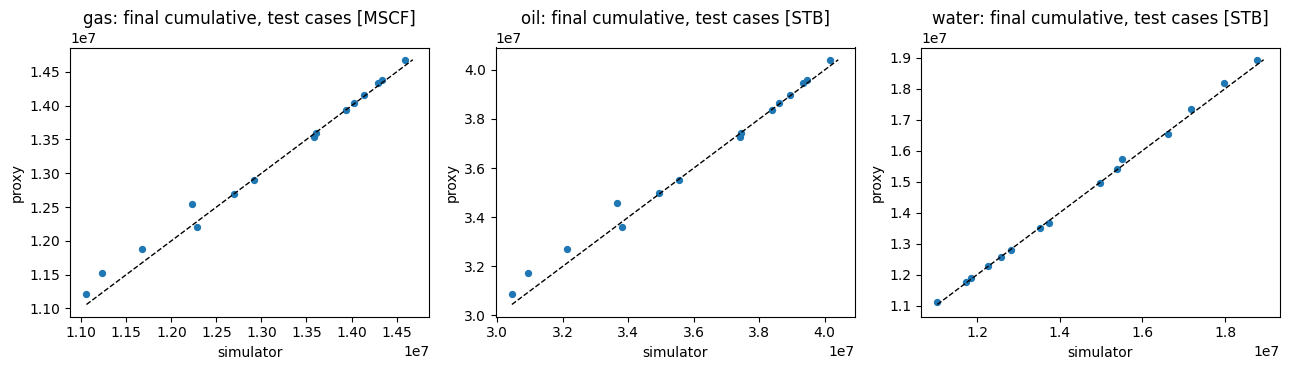

In [5]:
# refit on train+val, score ONCE on test, parity plot
proxy = Proxy(best_cfg.kind, int(best_cfg.n_pc)).fit(X[tr | va], Yflat[tr | va])
e_test = rmse_curves(proxy.predict(X[te]), Yflat[te])
print(f"TEST normalised RMSE: mean {e_test.mean():.5f}, max {e_test.max():.5f}")
PROXY_RMSE = float(e_test.mean())

pred_te = proxy.predict(X[te]).reshape(-1, T, 3)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for k, q in enumerate(Q):
    a, b = Y[te][:, -1, k], pred_te[:, -1, k] * scale[k]
    ax[k].scatter(a, b, s=18); m = [min(a.min(), b.min()), max(a.max(), b.max())]
    ax[k].plot(m, m, "k--", lw=1); ax[k].set_title(f"{q}: final cumulative, test cases [{UNIT[q]}]")
    ax[k].set_xlabel("simulator"); ax[k].set_ylabel("proxy")
plt.tight_layout(); plt.show()


## 2. History matching – find the best parameters (differential evolution)
Objective = weighted RMS difference between proxy curves and observed history (normalised units).
Several independent runs show whether the answer is unique. Search happens in the scaled box [0,1]^4
(= the train range), so the proxy is never asked to extrapolate.

In [6]:
# objective + differential evolution
def misfit(Xs):
    """Vectorised objective: Xs (n,4) scaled params -> (n,) weighted RMS misfit to the history."""
    pred = proxy.predict(Xs).reshape(-1, T, 3)
    return np.sqrt(np.mean(W[None, :, None] * (pred - obs[None]) ** 2, axis=(1, 2)))

de_x, de_f = [], []
for r in range(N_DE_RUNS):
    out = differential_evolution(lambda m: misfit(m.T), [(0, 1)] * 4, vectorized=True, updating="deferred",
                                 popsize=30, maxiter=300, tol=1e-10, seed=SEED + r, polish=True)
    de_x.append(out.x); de_f.append(out.fun)
de_x, de_f = np.array(de_x), np.array(de_f)
best_i = int(np.argmin(de_f)); best_x, best_fit = de_x[best_i], float(de_f[best_i])

tab = pd.DataFrame(to_orig(de_x), columns=P).assign(misfit=de_f).sort_values("misfit")
print("Differential evolution – one row per independent run (original units):")
print(tab.round(4).to_string(index=False))
print(f"\nBest misfit {best_fit:.5f}   |   spread of the {N_DE_RUNS} solutions / full range:",
      dict(zip(P, np.round(de_x.std(0), 2))))
edge = [P[i] for i in range(4) if best_x[i] < 0.01 or best_x[i] > 0.99]
print("Parameters sitting on the edge of the search box at the best fit:", edge or "none")


Differential evolution – one row per independent run (original units):
 fault_trans  poro_mult  perm_mult  aquifer_pv  misfit
        0.15     1.3886     0.5375    199.8352  0.0038
        0.15     1.3886     0.5375    199.8352  0.0038
        0.15     1.3886     0.5375    199.8352  0.0038
        0.15     1.3886     0.5375    199.8352  0.0038
        0.15     1.3886     0.5375    199.8352  0.0038
        0.15     1.3886     0.5375    199.8352  0.0038
        0.15     1.3886     0.5375    199.8352  0.0038
        0.15     1.3886     0.5375    199.8352  0.0038
        0.15     1.3886     0.5375    199.8352  0.0038
        0.15     1.3886     0.5375    199.8352  0.0038

Best misfit 0.00379   |   spread of the 10 solutions / full range: {'fault_trans': np.float64(0.0), 'poro_mult': np.float64(0.0), 'perm_mult': np.float64(0.0), 'aquifer_pv': np.float64(0.0)}
Parameters sitting on the edge of the search box at the best fit: ['fault_trans', 'perm_mult', 'aquifer_pv']


How to read this table:
* Runs that **disagree** on a parameter → the history cannot pin that parameter down.
* Runs that **all agree**, especially on a value at the **edge** of the box (printed above), mean the proxy's
  optimum is on the boundary. Do not treat that single best fit as "the truth": if the misfit barely changes
  across the posterior (section 3), the valley is flat and many other parameter sets match almost as well.
Either way we keep **several** parameter sets rather than one best one.

## 3. Posterior sampling (Bayesian MCMC, affine-invariant ensemble sampler)
Likelihood: Gaussian, `-0.5 * N_EFF * misfit² / sigma²`, uniform prior on the train range.
* `sigma` = total mismatch scale = sqrt(best-fit misfit² + proxy test error²).
* `N_EFF`: the 41×3 history values lie on smooth curves and are strongly correlated, so they carry far
  fewer than 123 independent pieces of evidence. 10 is a heuristic – **a larger N_EFF gives a narrower
  posterior**. Try 5 / 10 / 30 and see how the selected cases change.
The sampler (Goodman-Weare stretch move) is written out below, so no extra package is required.

In [7]:
# sampler
SIGMA = float(np.sqrt(best_fit ** 2 + PROXY_RMSE ** 2))

def logp(Xs):
    out = np.full(len(Xs), -np.inf)
    ok = np.all((Xs >= 0) & (Xs <= 1), axis=1)          # uniform prior inside the train box
    if ok.any():
        out[ok] = -0.5 * N_EFF * misfit(Xs[ok]) ** 2 / SIGMA ** 2
    return out

def aies(logp, p0, n_steps, a=2.0, rng=rng):
    nw, nd = p0.shape; half = nw // 2
    Xc, lp = p0.copy(), logp(p0)
    chain, lps, acc = np.empty((n_steps, nw, nd)), np.empty((n_steps, nw)), 0
    for t in range(n_steps):
        for S, O in ((slice(0, half), slice(half, nw)), (slice(half, nw), slice(0, half))):
            Xs, Xo = Xc[S], Xc[O]; n = len(Xs)
            zz = ((a - 1) * rng.random(n) + 1) ** 2 / a
            partner = Xo[rng.integers(0, len(Xo), n)]
            prop = partner + zz[:, None] * (Xs - partner)
            lpp = logp(prop)
            ok = np.log(rng.random(n)) < (nd - 1) * np.log(zz) + lpp - lp[S]
            Xc[S][ok] = prop[ok]; lp[S][ok] = lpp[ok]; acc += ok.sum()
        chain[t], lps[t] = Xc, lp
    return chain, lps, acc / (n_steps * nw)

def autocorr_time(chain):
    n, nw, nd = chain.shape; taus = []
    for d in range(nd):
        f = np.zeros(n)
        for w in range(nw):
            x = chain[:, w, d] - chain[:, w, d].mean()
            ac = np.correlate(x, x, "full")[n - 1:]; f += ac / ac[0]
        f /= nw; tau = 1.0
        for m in range(1, n):
            tau = 1 + 2 * f[1:m + 1].sum()
            if m >= 5 * tau: break
        taus.append(tau)
    return np.array(taus)


acceptance fraction 0.43 (healthy: 0.2-0.5)
autocorrelation time per parameter: {'fault_trans': np.float64(106.2), 'poro_mult': np.float64(95.3), 'perm_mult': np.float64(90.6), 'aquifer_pv': np.float64(88.9)}
post-burn-in length / tau (want > 50): [38. 42. 44. 45.]


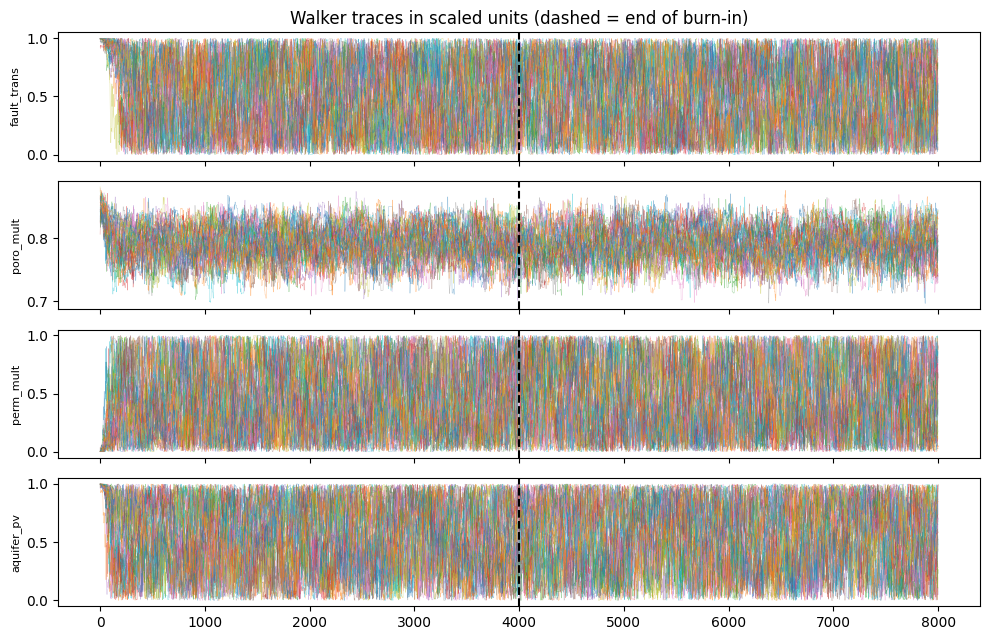

In [8]:
# run MCMC
start = de_x[rng.integers(0, N_DE_RUNS, N_WALKERS)] + 0.02 * rng.standard_normal((N_WALKERS, 4))
start = np.clip(start, 0.001, 0.999)
chain, lps, acc = aies(logp, start, N_STEPS)
burn = N_STEPS // 2
tau = autocorr_time(chain[burn:])
print(f"acceptance fraction {acc:.2f} (healthy: 0.2-0.5)")
print("autocorrelation time per parameter:", dict(zip(P, tau.round(1))))
print("post-burn-in length / tau (want > 50):", (chain[burn:].shape[0] / tau).round(0))

fig, ax = plt.subplots(4, 1, figsize=(10, 6.5), sharex=True)
for d in range(4):
    ax[d].plot(chain[:, :, d], lw=.3, alpha=.5); ax[d].set_ylabel(P[d], fontsize=8)
    ax[d].axvline(burn, c="k", ls="--")
ax[0].set_title("Walker traces in scaled units (dashed = end of burn-in)")
plt.tight_layout(); plt.show()


In [9]:
# posterior samples
step = max(1, int(np.ceil(tau.max())))
post = chain[burn::step].reshape(-1, 4)                  # thinned, post burn-in
post_mis = misfit(post)
print(f"{len(post)} thinned posterior samples; misfit median {np.median(post_mis):.5f}, "
      f"best {post_mis.min():.5f}")
pq = pd.DataFrame(to_orig(post), columns=P).quantile([.05, .5, .95]).round(4)
print("\nPosterior 5% / 50% / 95% (original units):\n", pq.to_string())
print("Prior ranges (train bounds):\n", pd.DataFrame({"min": lo, "max": hi}, index=P).round(4).T.to_string())


1216 thinned posterior samples; misfit median 0.00429, best 0.00381

Posterior 5% / 50% / 95% (original units):
       fault_trans  poro_mult  perm_mult  aquifer_pv
0.05       0.0561     1.3186     0.9779     67.3040
0.50       0.1025     1.3487     4.7010    140.2336
0.95       0.1451     1.3791     9.0912    194.6137
Prior ranges (train bounds):
      fault_trans  poro_mult  perm_mult  aquifer_pv
min       0.0508     0.8012     0.5375     53.9529
max       0.1500     1.4940     9.5020    199.8352


## 4. Choose the 10 cases for the forecast
From the better half of the posterior (lowest misfit), cluster in parameter space with k-means and keep
the lowest-misfit sample of every cluster → **diverse AND well-matching**.

In [10]:
# select diverse top cases
good = post_mis <= np.quantile(post_mis, 0.5)
Pg, Mg = post[good], post_mis[good]
km = KMeans(N_SELECT, n_init=10, random_state=SEED).fit(Pg)
pick = [np.where(km.labels_ == c)[0][np.argmin(Mg[km.labels_ == c])] for c in range(N_SELECT)]
sel_s = Pg[pick]
sel_mis = Mg[pick]
_, sel_unc = proxy.predict(sel_s, return_unc=True)

order = np.argsort(sel_mis)
sel = pd.DataFrame(to_orig(sel_s[order]), columns=P)
sel.insert(0, "rank", np.arange(1, N_SELECT + 1))
for j, p in enumerate(PS): sel[p] = sel_s[order][:, j]
sel["misfit"] = sel_mis[order]
if sel_unc is not None: sel["proxy_unc"] = sel_unc[order]
print(sel.round(4).to_string(index=False))
print(f"\nMisfit of the selected cases: {sel_mis.min():.5f} - {sel_mis.max():.5f}")
if sel_unc is not None:
    print(f"Typical proxy uncertainty at those points: {np.mean(sel_unc):.5f}")
    print("-> if the proxy uncertainty is about as large as the misfit differences, the ranking inside the 10 is"
          " not meaningful: treat all 10 as equally acceptable matches.")
sel.to_csv("hm_selected_cases.csv", index=False)
np.savez("hm_posterior.npz", post=post, post_misfit=post_mis, best_x=best_x, sigma=SIGMA)


 rank  fault_trans  poro_mult  perm_mult  aquifer_pv  fault_trans_s  poro_mult_s  perm_mult_s  aquifer_pv_s  misfit  proxy_unc
    1       0.0613     1.3856     0.7056    192.0529         0.1062       0.8435       0.0188        0.9467  0.0038     0.0038
    2       0.0883     1.3823     0.9959    197.7106         0.3788       0.8387       0.0511        0.9854  0.0038     0.0038
    3       0.1407     1.3809     1.0646    172.7025         0.9071       0.8367       0.0588        0.8140  0.0038     0.0038
    4       0.1374     1.3770     1.1249    152.6366         0.8738       0.8310       0.0655        0.6765  0.0039     0.0038
    5       0.0752     1.3763     0.7775    144.7887         0.2465       0.8301       0.0268        0.6227  0.0039     0.0038
    6       0.1225     1.3436     8.9068    198.3045         0.7235       0.7829       0.9336        0.9895  0.0040     0.0038
    7       0.0728     1.3433     9.3346    192.3107         0.2218       0.7825       0.9813        0.9484  0.

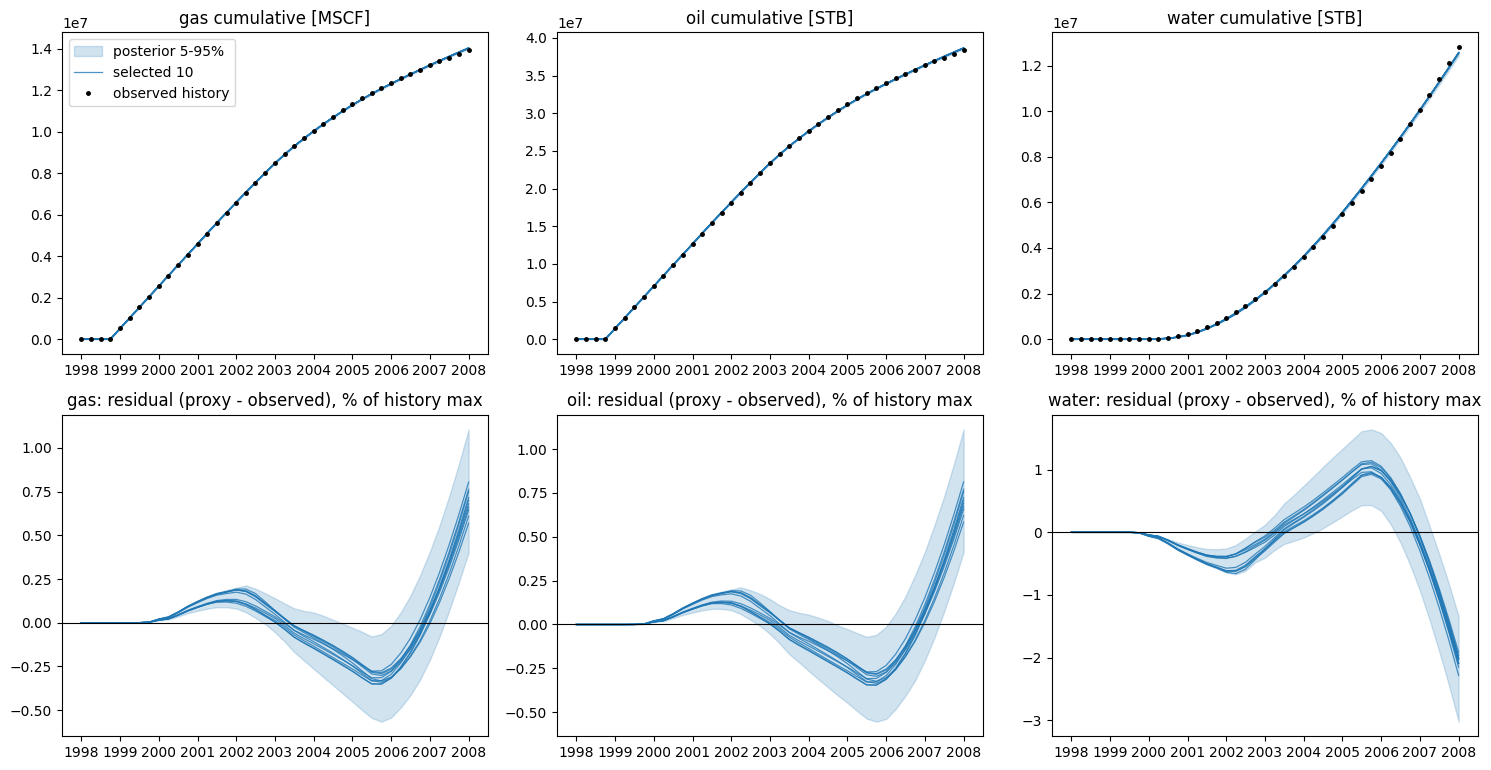

In [11]:
# plot history match
pred_sel = proxy.predict(sel_s[order]).reshape(-1, T, 3) * scale
pred_post = proxy.predict(post[np.random.default_rng(1).choice(len(post), min(300, len(post)), replace=False)]
                          ).reshape(-1, T, 3) * scale
fig, ax = plt.subplots(2, 3, figsize=(15, 7.8))
for k, q in enumerate(Q):
    # top: cumulative curves
    ax[0, k].fill_between(dates, np.percentile(pred_post[:, :, k], 5, 0), np.percentile(pred_post[:, :, k], 95, 0),
                          color="tab:blue", alpha=.2, label="posterior 5-95%")
    for i in range(N_SELECT):
        ax[0, k].plot(dates, pred_sel[i, :, k], color="tab:blue", lw=.9, alpha=.8, label="selected 10" if i == 0 else None)
    ax[0, k].plot(dates, yh[:, k], "k.", ms=5, label="observed history")
    ax[0, k].set_title(f"{q} cumulative [{UNIT[q]}]")
    # bottom: residual (proxy - observed) as % of the observed maximum -> makes the small differences visible
    res_post = (pred_post[:, :, k] - yh[None, :, k]) / scale[k] * 100
    ax[1, k].fill_between(dates, np.percentile(res_post, 5, 0), np.percentile(res_post, 95, 0), color="tab:blue", alpha=.2)
    for i in range(N_SELECT):
        ax[1, k].plot(dates, (pred_sel[i, :, k] - yh[:, k]) / scale[k] * 100, color="tab:blue", lw=.9, alpha=.8)
    ax[1, k].axhline(0, c="k", lw=.8); ax[1, k].set_title(f"{q}: residual (proxy - observed), % of history max")
ax[0, 0].legend(); plt.tight_layout(); plt.show()


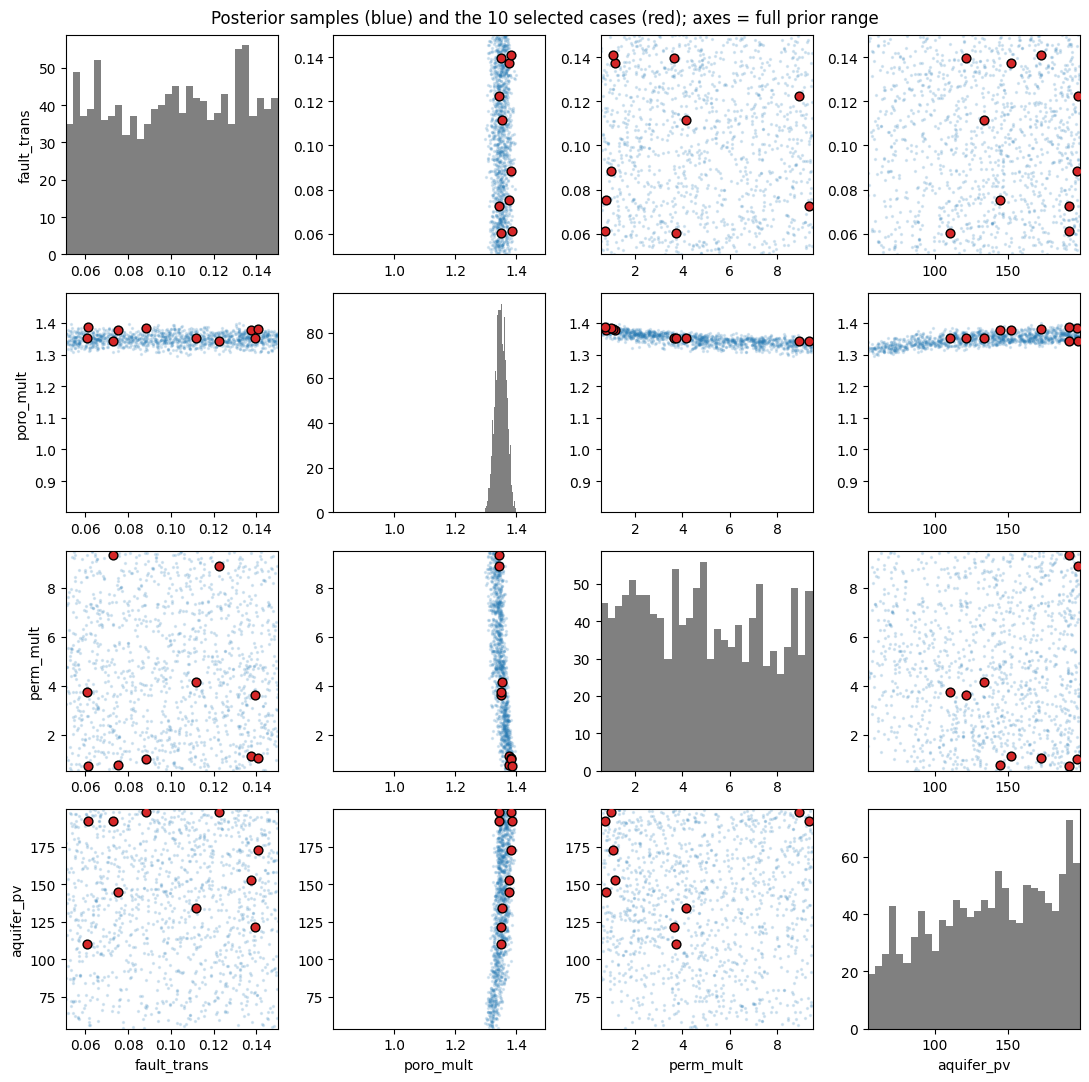

In [12]:
# plot posterior pairs
Po, Ps = to_orig(post), to_orig(sel_s)
fig, ax = plt.subplots(4, 4, figsize=(11, 11))
for i in range(4):
    for j in range(4):
        a = ax[i, j]
        if i == j:
            a.hist(Po[:, i], bins=30, color="grey"); a.set_xlim(lo[i], hi[i])
        else:
            a.scatter(Po[:, j], Po[:, i], s=2, alpha=.15, c="tab:blue")
            a.scatter(Ps[:, j], Ps[:, i], s=40, c="tab:red", edgecolor="k", zorder=3)
            a.set_xlim(lo[j], hi[j]); a.set_ylim(lo[i], hi[i])
        if i == 3: a.set_xlabel(P[j])
        if j == 0: a.set_ylabel(P[i])
plt.suptitle("Posterior samples (blue) and the 10 selected cases (red); axes = full prior range")
plt.tight_layout(); plt.show()


## Reading the results
* **Tight histogram** (narrow vs the axis range) → the history identifies that parameter; **flat/wide** →
  it does not, and the 10 selected cases deliberately span that uncertainty.
* Compare `proxy_unc` with the misfit differences between the selected cases. If they are similar, the proxy
  cannot rank those cases against each other (all 10 are equally acceptable), which is normal here.
* The best misfit cannot go meaningfully below the proxy's own test error (printed in section 1).
* `hm_selected_cases.csv` (original + scaled values) is the input to the **forecast stage**
  (extend each case to 2028 and fill the `09` template).